In [19]:
from IPython.display import display, Latex, Markdown
import numpy as np
import matplotlib.pyplot as plt


--- Convergence Study: f(x) = sin(x) ---
         h |           Error |        EOC
     1.000 |       4.910e-07 |        ---
     0.500 |       3.671e-09 |     7.0637
     0.250 |       2.730e-11 |     7.0708
     0.125 |       2.066e-13 |     7.0463
     0.062 |       1.513e-15 |     7.0934
     0.031 |       3.469e-18 |     8.7682
     0.016 |       1.735e-18 |     1.0000
     0.008 |       1.041e-17 |    -2.5850


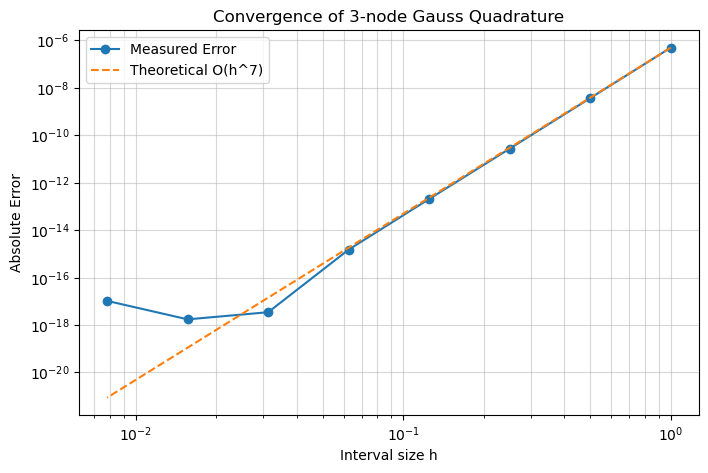

In [64]:
def gauss_quad_3node(f, a, b):
    # Standard nodes and weights for [-1, 1]
    nodes = np.array([-np.sqrt(3/5), 0, np.sqrt(3/5)])
    weights = np.array([5/9, 8/9, 5/9])
    
    # Map nodes to [a, b]
    mapped_nodes = 0.5 * (b - a) * nodes + 0.5 * (a + b)
    # Scaling factor for the integral
    integral = 0.5 * (b - a) * np.sum(weights * f(mapped_nodes))
    return integral

# --- 1. Convergence Study for f(x) = sin(x) ---
h_values = np.array([1.0 / (2**i) for i in range(8)])
errors = []
f = np.sin

for h in h_values:
    a, b = 1.0, 1.0 + h
    exact = -np.cos(b) + np.cos(a)
    approx = gauss_quad_3node(f, a, b)
    errors.append(abs(exact - approx))

errors = np.array(errors)
# Calculate EOC: log(err2/err1) / log(h2/h1)
eoc = np.log(errors[1:] / errors[:-1]) / np.log(h_values[1:] / h_values[:-1])

print("--- Convergence Study: f(x) = sin(x) ---")
print(f"{'h':>10} | {'Error':>15} | {'EOC':>10}")
for i in range(len(h_values)):
    eoc_val = f"{eoc[i-1]:.4f}" if i > 0 else "---"
    print(f"{h_values[i]:10.3f} | {errors[i]:15.3e} | {eoc_val:>10}")

# --- 2. Graphical Representation ---
plt.figure(figsize=(8, 5))
plt.loglog(h_values, errors, '-o', label='Measured Error')
# Plot a reference line for O(h^7)
plt.loglog(h_values, (h_values**7) * (errors[0]/h_values[0]**7), '--', label='Theoretical O(h^7)')
plt.xlabel('Interval size h')
plt.ylabel('Absolute Error')
plt.title('Convergence of 3-node Gauss Quadrature')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

In [46]:
# --- 3. Precision Test ---
print("\n--- Precision Test: Polynomials x^p on [0, 1] ---")
for p in range(4, 8):
    f_poly = lambda x: x**p
    exact = 1.0 / (p + 1)
    approx = gauss_quad_3node(f_poly, 0, 1)
    error = abs(exact - approx)
    print(f"Degree {p}: Error = {error:.2e} {'(Exact)' if error < 1e-14 else '(Inexact)'}")
    


--- Precision Test: Polynomials x^p on [0, 1] ---
Degree 4: Error = 0.00e+00 (Exact)
Degree 5: Error = 2.78e-17 (Exact)
Degree 6: Error = 3.57e-04 (Inexact)
Degree 7: Error = 1.25e-03 (Inexact)


The expected degree of precision is 2n-1 which is 5 in this case, 
exactly matches the result shown above.

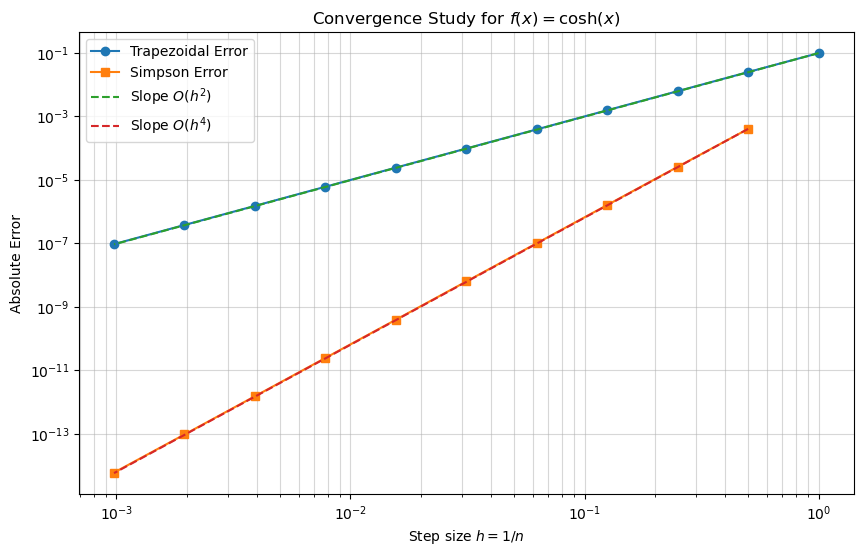

In [48]:
def composite_trapezoidal(f, a, b, n):
    x = np.linspace(a, b, n + 1)
    h = (b - a) / n
    y = f(x)
    return (h / 2) * (y[0] + 2 * np.sum(y[1:-1]) + y[-1])

def composite_simpson(f, a, b, n):
    if n % 2 != 0:
        raise ValueError("n must be even for Simpson's rule.")
    x = np.linspace(a, b, n + 1)
    h = (b - a) / n
    y = f(x)
    # Summing terms with weights 1, 4, 2, 4, ..., 2, 4, 1
    return (h / 3) * (y[0] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-2:2]) + y[-1])

# --- Convergence Study ---
f = np.cosh
a, b = 0, 1
exact_integral = np.sinh(b) - np.sinh(a)

k_values = np.arange(0, 11)
n_values = 2**k_values
h_values = (b - a) / n_values

trap_errors = []
simp_errors = []

for n in n_values:
    trap_val = composite_trapezoidal(f, a, b, n)
    trap_errors.append(abs(exact_integral - trap_val))
    
    # Simpson requires even n; n=2^0 is handled separately or skipped
    if n >= 2:
        simp_val = composite_simpson(f, a, b, n)
        simp_errors.append(abs(exact_integral - simp_val))
    else:
        simp_errors.append(np.nan)

# Plotting
plt.figure(figsize=(10, 6))
plt.loglog(h_values, trap_errors, 'o-', label='Trapezoidal Error')
plt.loglog(h_values, simp_errors, 's-', label='Simpson Error')

# Reference lines
plt.loglog(h_values, h_values**2 * (trap_errors[0]/h_values[0]**2), '--', label=r'Slope $O(h^2)$')
plt.loglog(h_values[1:], h_values[1:]**4 * (simp_errors[1]/h_values[1]**4), '--', label=r'Slope $O(h^4)$')

plt.xlabel(r'Step size $h = 1/n$')
plt.ylabel('Absolute Error')
plt.title(r'Convergence Study for $f(x) = \cosh(x)$')
plt.legend()
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.show()

$$|E_T| \leq \frac{(b-a)^3}{12n^2} \max_{x \in [a,b]} |f''(x)|$$
For $f(x) = (\ln x)^{-1}$, the second derivative is:$$f''(x) = \frac{\ln x + 2}{x^2 (\ln x)^3}$$Since $f''(x)$ is strictly decreasing on $[2, 3]$, its maximum occurs at the left endpoint $x=2$:$$M_2 = \max_{x \in [2,3]} |f''(x)| = f''(2) = \frac{\ln 2 + 2}{4 (\ln 2)^3} \approx 2.0217$$
$$n^2 > \frac{2.0217}{12 \times 10^{-5}} \implies n > \sqrt{16847.5} \approx 129.8$$

In [60]:
f_inv_ln = lambda x: 1 / np.log(x)
result = composite_trapezoidal(f_inv_ln, 2, 3, 130)
print(f"Approximated Integral: {result:.3f}")

Approximated Integral: 1.118


The error is definitely lower than $10^{-5}$ because:  
1.Conservative Bound: We used the global maximum $M_2$ of the absolute value of the second derivative over the entire interval. In the actual error formula $E_n = -\frac{h^2}{12}(b-a)f''(\xi)$, the point $\xi$ is some unknown point in $(2, 3)$. Since $f''(x)$ is strictly decreasing, $|f''(\xi)|$ is strictly less than $M_2 = f''(2)$ for any $\xi > $.  
2.Sufficient $n$: By rounding $n$ up to $130$, we ensure that $\frac{M_2}{12n^2} < 10^{-5}$ is satisfied.  
3.Function Smoothness: The function $f(x) = \frac{1}{\ln x}$ is $C^\infty$ (infinitely differentiable) on $[2, 3]$, ensuring the standard error formula for the trapezoidal rule is valid and reliable.

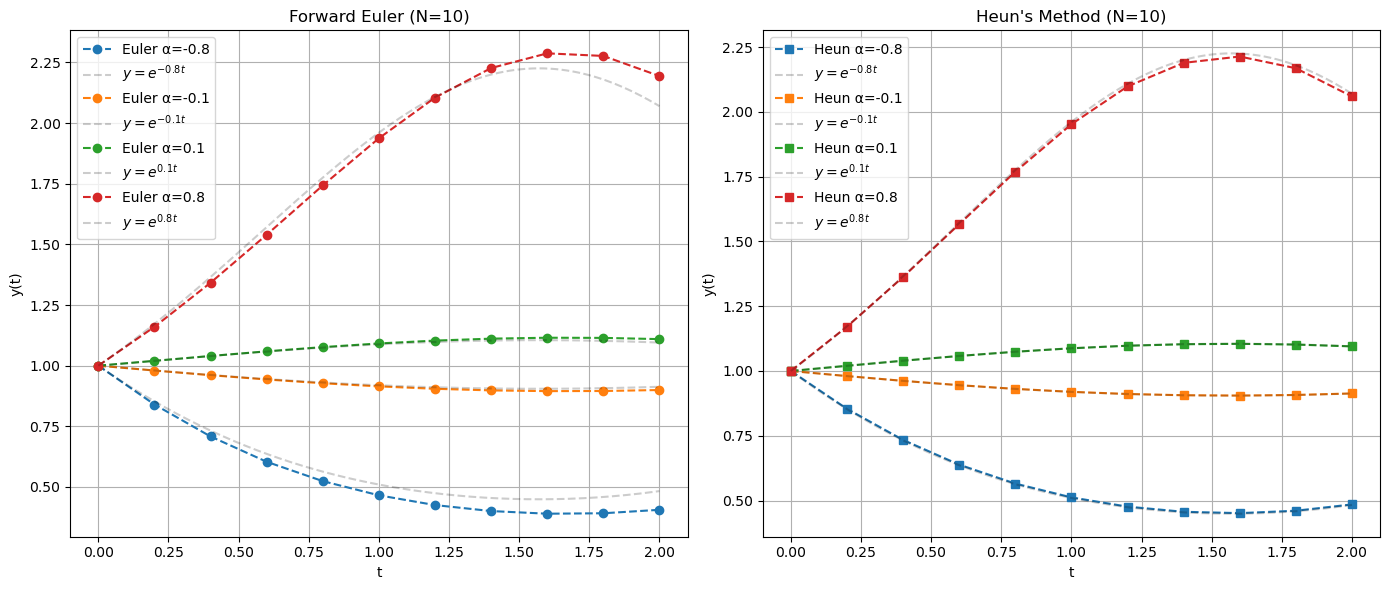

In [59]:
import numpy as np
import matplotlib.pyplot as plt

def f(t, y, alpha):
    return alpha * np.cos(t) * y

def exact_sol(t, alpha):
    return np.exp(alpha * np.sin(t))

def solve_ivp(alpha, N=10, T=2, method='euler'):
    t = np.linspace(0, T, N+1)
    h = T / N
    u = np.zeros(N+1)
    u[0] = 1
    for n in range(N):
        if method == 'euler':
            u[n+1] = u[n] + h * f(t[n], u[n], alpha)
        elif method == 'heun':
            k1 = f(t[n], u[n], alpha)
            k2 = f(t[n+1], u[n] + h * k1, alpha)
            u[n+1] = u[n] + (h/2) * (k1 + k2)
    return t, u

alphas = [-0.8, -0.1, 0.1, 0.8]
t_fine = np.linspace(0, 2, 200)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

for a in alphas:
    # Euler Plot
    t_n, u_e = solve_ivp(a, method='euler')
    ax1.plot(t_n, u_e, 'o--', label=f'Euler α={a}')
    ax1.plot(t_fine, exact_sol(t_fine, a),'k--', alpha=0.2,label=f'$y= e^{{{a} t}}$ ')
    
    # Heun Plot
    t_n, u_h = solve_ivp(a, method='heun')
    ax2.plot(t_n, u_h, 's--', label=f'Heun α={a}')
    ax2.plot(t_fine, exact_sol(t_fine, a), 'k--', alpha=0.2,label=f'$y= e^{{{a} t}}$ ')

ax1.set_title("Forward Euler (N=10)"); ax2.set_title("Heun's Method (N=10)")
for ax in [ax1, ax2]:
    ax.legend(); ax.grid(True); ax.set_xlabel("t"); ax.set_ylabel("y(t)")

plt.tight_layout()
plt.show()

Comment and Comparison: 
1.Accuracy: Even with a coarse discretization ($N=10$), Heun's method is visibly superior. While the Forward Euler results "drift" significantly from the light-colored exact curves, the Heun results stay almost perfectly aligned.  
2.Order of Convergence: Forward Euler is a first-order method ($O(h)$), meaning the error is proportional to the step size. Heun’s method is a second-order method ($O(h^2)$). Because $h=0.2$ is relatively large, the quadratic reduction in error for Heun makes a massive difference in stability and precision.  
3.Behavior for $\alpha$: For positive $\alpha$, the solution grows initially. Euler tends to overshoot the growth because it assumes the initial (maximum) slope is constant throughout the interval.For negative $\alpha$, the solution decays. Euler similarly struggles to capture the slowing rate of decay.Heun's method corrects these issues by averaging the slopes at both ends of the interval, effectively accounting for the curvature of the solution.